# Частина 1. Власне донавчання: визначення токсичних коментарів українською

**Задача.** Модератор україномовного телеграм-каналу чи коментарів під новинами хоче автоматично позначати токсичні повідомлення (образи, лайка, приниження), щоб переглядати лише їх. **Вхід** — текст коментаря/твіту українською. **Вихід** — мітка `0` (нетоксичний) або `1` (токсичний) і ймовірність.

Метод — **класичне донавчання з новою головою** (як у демо 1): мультимовний енкодер **XLM-RoBERTa-base** + лінійний класифікатор на 2 класи, повне донавчання всіх ваг. Порівнюємо з базовими підходами: «завжди найчастіший клас» і LLM із підібраним промптом (Qwen3-1.7B, few-shot).

Для запуску в Colab: *Runtime → Change runtime type → T4 GPU*.

In [ ]:
!pip install -q "transformers>=4.55.0" datasets accelerate scikit-learn

In [ ]:
import gc, json, re, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset, DatasetDict
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from transformers import (AutoModelForSequenceClassification, AutoModelForCausalLM, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)

set_seed(42)
assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
print("GPU:", torch.cuda.get_device_name())

GPU: Tesla T4


## 1. Дані

[**ukr-detect/ukr-toxicity-dataset**](https://huggingface.co/datasets/ukr-detect/ukr-toxicity-dataset) — 5 000 українських твітів, розмічених краудсорсингом (Toloka) на токсичні (`toxic=1`) і нетоксичні (`toxic=0`), класи збалансовані 50/50. Ліцензія — OpenRAIL. Формат — TSV з колонками `text`, `toxic`.

⚠️ Датасет містить нецензурну лексику; приклади нижче показано лише для аналізу роботи моделі.

In [ ]:
raw = load_dataset("ukr-detect/ukr-toxicity-dataset", split="train")
print(raw)
df = raw.to_pandas()
print(df["toxic"].value_counts())
print("Середня довжина, символів:", int(df["text"].str.len().mean()))
df.sample(6, random_state=1)

README.md:   0%|          | 0.00/2.29k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/587k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'toxic'],
    num_rows: 5000
})
toxic
0    2500
1    2500
Name: count, dtype: int64
Середня довжина, символів: 63


,text,toxic
2764,"Лист від СБУ - ахуєнна шутка, куди тут аплодув...",1
4767,"Блядь, коли фраза ""я не збираюсь з вами розмов...",1
3814,"Хто б іще вам сказав, які ви мразі.",1
3499,З печери в Кам'янець нас віз російськомовний т...,1
2735,Спершу випускають своїх піздюків грати на доро...,1
3922,"- Та бля, вино з дині!",1


### Очищення й розбиття

Прибираємо дублікати (однаковий текст без урахування регістру й пробілів), щоб той самий твіт не потрапив і в train, і в test. Потім стратифіковано ділимо **80 / 10 / 10**: train — для навчання, validation — для вибору епохи й контролю перенавчання, test — лише для фінальної оцінки (до тренування його не використовуємо).

In [ ]:
df["key"] = df["text"].str.strip().str.lower()
before = len(df)
df = df.drop_duplicates("key").drop(columns="key").reset_index(drop=True)
print(f"Дублікатів прибрано: {before - len(df)}, лишилось {len(df)}")

from sklearn.model_selection import train_test_split
train_df, tmp_df = train_test_split(df, test_size=0.2, stratify=df["toxic"], random_state=42)
val_df, test_df = train_test_split(tmp_df, test_size=0.5, stratify=tmp_df["toxic"], random_state=42)
assert not set(train_df.text) & set(test_df.text) and not set(train_df.text) & set(val_df.text)
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10} {len(part):5} прикладів, токсичних {part.toxic.mean():.1%}")

Дублікатів прибрано: 3, лишилось 4997
train       3997 прикладів, токсичних 50.0%
validation   500 прикладів, токсичних 50.0%
test         500 прикладів, токсичних 50.0%


## 2. Метрика й результати до донавчання

**Метрика — macro-F1** (середнє F1 для обох класів) плюс accuracy, precision і recall для класу «токсичний». F1 враховує і пропущені токсичні коментарі (recall), і хибні тривоги (precision); macro-усереднення не дає «сховати» поганий результат на одному класі. Класи збалансовані, тому accuracy теж інформативна, але для модерації важливо бачити окремо precision/recall.

### Базовий рівень 1: «завжди найчастіший клас»

In [ ]:
def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro-F1": f1_score(y_true, y_pred, average="macro"),
            "precision (toxic)": precision_score(y_true, y_pred, zero_division=0),
            "recall (toxic)": recall_score(y_true, y_pred, zero_division=0)}

y_test = test_df["toxic"].values
majority = int(train_df["toxic"].mode()[0])
results = {"Найчастіший клас": metrics(y_test, np.full(len(y_test), majority))}
pd.DataFrame(results).round(3)

,Найчастіший клас
accuracy,0.500
macro-F1,0.333
precision (toxic),0.000
recall (toxic),0.000


### Базовий рівень 2: LLM з найкращим промптом (без донавчання)

Чи можна обійтися без донавчання? Беремо instruct-модель **Qwen3-1.7B** і підібраний промпт: визначення токсичності, вимога відповідати однією цифрою і 4 приклади (few-shot). Міркування вимкнено, генерація жадібна.

In [ ]:
llm_name = "Qwen/Qwen3-1.7B"
llm_tok = AutoTokenizer.from_pretrained(llm_name)
llm = AutoModelForCausalLM.from_pretrained(llm_name, dtype=torch.float16, device_map="auto")

SYSTEM = ("Ти модератор коментарів українською мовою. Визнач, чи є коментар токсичним: "
          "містить образи, лайку, нецензурні слова, приниження чи погрози. "
          "Відповідай лише однією цифрою: 1 — токсичний, 0 — нетоксичний.")
FEW_SHOT = [("Дякую за статтю, дуже корисно!", "0"), ("Ти тупий ідіот, закрий рота", "1"),
            ("Сьогодні у Львові дощ і холодно", "0"), ("Пішов ти на х*й зі своєю думкою", "1")]

def llm_prompt(text):
    msgs = [{"role": "system", "content": SYSTEM}]
    for t, a in FEW_SHOT:
        msgs += [{"role": "user", "content": t}, {"role": "assistant", "content": a}]
    msgs.append({"role": "user", "content": text})
    return llm_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def llm_classify(texts, bs=32):
    preds, raw_answers = [], []
    llm_tok.padding_side = "left"
    for i in range(0, len(texts), bs):
        batch = [llm_prompt(t) for t in texts[i:i + bs]]
        inp = llm_tok(batch, return_tensors="pt", padding=True).to(llm.device)
        with torch.no_grad():
            out = llm.generate(**inp, max_new_tokens=5, do_sample=False, pad_token_id=llm_tok.pad_token_id)
        for a in llm_tok.batch_decode(out[:, inp["input_ids"].shape[1]:], skip_special_tokens=True):
            raw_answers.append(a.strip())
            m = re.search(r"[01]", a)
            preds.append(int(m.group()) if m else 0)   # нерозпізнана відповідь = нетоксичний
    return np.array(preds), raw_answers

t0 = time.time()
llm_pred, llm_raw = llm_classify(test_df["text"].tolist())
print(f"Час: {time.time() - t0:.0f} с; нерозпізнаних відповідей: {sum(not re.search('[01]', a) for a in llm_raw)}")
results["Qwen3-1.7B + few-shot промпт"] = metrics(y_test, llm_pred)
pd.DataFrame(results).round(3)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Час: 39 с; нерозпізнаних відповідей: 0


,Найчастіший клас,Qwen3-1.7B + few-shot промпт
accuracy,0.500,0.656
macro-F1,0.333,0.641
precision (toxic),0.000,0.611
recall (toxic),0.000,0.860


In [ ]:
print("Приклади відповідей LLM на тестовому наборі:")
for t, y, p in list(zip(test_df.text, y_test, llm_pred))[:10]:
    print(f"{'✅' if y == p else '❌'} еталон={y} LLM={p} | {t[:110]}")
del llm; gc.collect(); torch.cuda.empty_cache()

Приклади відповідей LLM на тестовому наборі:
✅ еталон=0 LLM=0 | Найбільшим визнанням своїх статусів у фб вважаю лайк від мого улюбленого викладача.
✅ еталон=1 LLM=1 | Конкретної інфи й пояснень чому все хуйово, я не бачу, а отже то чисто загон
✅ еталон=1 LLM=1 | Оцінював як швидко тебе можна спіздіть
❌ еталон=0 LLM=1 | Ще 2 офігенних мужиків запросило на каву...
✅ еталон=1 LLM=1 | це йобана фантасмагорія, яка точно закінчиться улюбленим та рідним для свинособак ядерним попілом. скрізь хуйн
❌ еталон=1 LLM=0 | Я звичайно не надто музику у вк слухав,  але бляха, як я тепер без класних аудіо  ?
✅ еталон=1 LLM=1 | Всьо, парішав питання з одним пройобаним екзаменом Можна жити
✅ еталон=0 LLM=0 | та ні, це нормальний стан речей. зрадники зраджують, злодії крадуть, вбивці убивають, а закохані люблять один 
✅ еталон=1 LLM=1 | Педосинно-український #словник: Добрідень-ти хто такий?Звітки приїхав і до кого?Шо привіз і кому?
❌ еталон=0 LLM=1 | Нарізав вам фрагменти вчорашнього ефіру з Мураєвим.


### Базовий рівень 3: XLM-RoBERTa з новою, ще не навченою головою

In [ ]:
MODEL = "FacebookAI/xlm-roberta-base"
tok = AutoTokenizer.from_pretrained(MODEL)
ds = DatasetDict({k: __import__("datasets").Dataset.from_pandas(v.rename(columns={"toxic": "label"})[["text", "label"]], preserve_index=False)
                  for k, v in [("train", train_df), ("validation", val_df), ("test", test_df)]})
ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True)
collator = DataCollatorWithPadding(tok)
lengths = [len(x) for x in ds["train"]["input_ids"]]
print(f"Довжина в токенах: медіана {int(np.median(lengths))}, 99-й перцентиль {int(np.percentile(lengths, 99))}, обрізано до 128: {np.mean(np.array(lengths) >= 128):.1%}")

def compute_metrics(p):
    logits, labels = p
    return {k.split(" ")[0]: v for k, v in metrics(labels, logits.argmax(-1)).items()}

set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)
untrained = Trainer(model=model, args=TrainingArguments("tmp", per_device_eval_batch_size=64, report_to="none"),
                    data_collator=collator)
results["XLM-R, голова до навчання"] = metrics(y_test, untrained.predict(ds["test"]).predictions.argmax(-1))
pd.DataFrame(results).round(3)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/3997 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Найчастіший клас,Qwen3-1.7B + few-shot промпт,"XLM-R, голова до навчання"
accuracy,0.500,0.656,0.500
macro-F1,0.333,0.641,0.333
precision (toxic),0.000,0.611,0.000
recall (toxic),0.000,0.860,0.000


## 3. Донавчання

**Метод:** повне донавчання XLM-RoBERTa-base (278 млн параметрів) з новою головою `classifier` на 2 класи.

**Гіперпараметри:**
- `learning_rate=2e-5` — малий крок, щоб не зруйнувати мовні знання, отримані під час попереднього тренування; лінійне зменшення з розігрівом на перших 100 кроках (≈10% із 1000);
- `num_train_epochs=4` — на ~4 тис. прикладів 2–4 епох зазвичай достатньо; найкращу епоху вибираємо за macro-F1 на валідації (`load_best_model_at_end`), щоб не взяти перенавчену модель;
- `per_device_train_batch_size=16`, `max_length=128` (майже всі твіти коротші);
- `weight_decay=0.01` — регуляризація; `fp16=True` — змішана точність на T4.

In [ ]:
args = TrainingArguments(
    output_dir="xlmr-toxic", num_train_epochs=4, learning_rate=2e-5, warmup_steps=100,  # ≈10% з 1000 кроків (250 кроків/епоха × 4)
    weight_decay=0.01,
    per_device_train_batch_size=16, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="macro-F1",
    logging_strategy="epoch", fp16=True, report_to="none", seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["validation"],
                  data_collator=collator, compute_metrics=compute_metrics)
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
train_minutes = (time.time() - t0) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"Тривалість: {train_minutes:.1f} хв, пікова памʼять GPU: {peak_gb:.1f} GB")

Epoch,Training Loss,Validation Loss,Accuracy,Macro-f1,Precision,Recall
1,0.550742,0.327051,0.878000,0.877917,0.898734,0.852000
2,0.298663,0.333788,0.892000,0.891972,0.879845,0.908000
3,0.206364,0.426685,0.896000,0.895893,0.872180,0.928000
4,0.157945,0.519536,0.896000,0.895918,0.875000,0.924000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Тривалість: 5.6 хв, пікова памʼять GPU: 4.7 GB


,епоха,train loss,val loss,val accuracy,val macro-F1
0,1,0.5507,0.3271,0.878,0.8779
1,2,0.2987,0.3338,0.892,0.8920
2,3,0.2064,0.4267,0.896,0.8959
3,4,0.1579,0.5195,0.896,0.8959


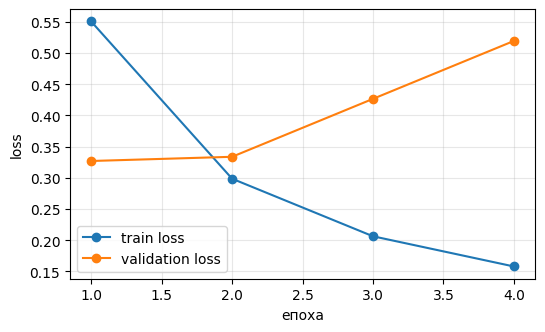

In [ ]:
hist = trainer.state.log_history
tl = {round(h["epoch"]): h["loss"] for h in hist if "loss" in h}
log = pd.DataFrame([{"епоха": round(h["epoch"]), "train loss": tl.get(round(h["epoch"])), "val loss": h["eval_loss"],
                     "val accuracy": h["eval_accuracy"], "val macro-F1": h["eval_macro-F1"]} for h in hist if "eval_loss" in h])
display(log.round(4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(log["епоха"], log["train loss"], "o-", label="train loss")
ax.plot(log["епоха"], log["val loss"], "o-", label="validation loss")
ax.set_xlabel("епоха"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 4. Порівняння на тестовому наборі

In [ ]:
pred = trainer.predict(ds["test"])
probs = torch.tensor(pred.predictions).float().softmax(-1)[:, 1].numpy()
ft_pred = pred.predictions.argmax(-1)
results["XLM-R після донавчання"] = metrics(y_test, ft_pred)
summary = pd.DataFrame(results).T.round(3)
display(summary)
print("Матриця помилок (рядки — еталон 0/1, стовпці — прогноз 0/1):")
print(confusion_matrix(y_test, ft_pred))

,accuracy,macro-F1,precision (toxic),recall (toxic)
Найчастіший клас,0.500,0.333,0.000,0.000
Qwen3-1.7B + few-shot промпт,0.656,0.641,0.611,0.860
"XLM-R, голова до навчання",0.500,0.333,0.000,0.000
XLM-R після донавчання,0.906,0.906,0.892,0.924


Матриця помилок (рядки — еталон 0/1, стовпці — прогноз 0/1):
[[222  28]
 [ 19 231]]


In [ ]:
print("Ті самі 10 прикладів, що й для LLM:")
for t, y, pl, pf, pr in list(zip(test_df.text, y_test, llm_pred, ft_pred, probs))[:10]:
    print(f"еталон={y} | LLM={pl} | донавчена={pf} ({pr:.0%}) | {t[:100]}")

Ті самі 10 прикладів, що й для LLM:
еталон=0 | LLM=0 | донавчена=0 (0%) | Найбільшим визнанням своїх статусів у фб вважаю лайк від мого улюбленого викладача.
еталон=1 | LLM=1 | донавчена=1 (100%) | Конкретної інфи й пояснень чому все хуйово, я не бачу, а отже то чисто загон
еталон=1 | LLM=1 | донавчена=1 (100%) | Оцінював як швидко тебе можна спіздіть
еталон=0 | LLM=1 | донавчена=0 (0%) | Ще 2 офігенних мужиків запросило на каву...
еталон=1 | LLM=1 | донавчена=1 (100%) | це йобана фантасмагорія, яка точно закінчиться улюбленим та рідним для свинособак ядерним попілом. с
еталон=1 | LLM=0 | донавчена=1 (100%) | Я звичайно не надто музику у вк слухав,  але бляха, як я тепер без класних аудіо  ?
еталон=1 | LLM=1 | донавчена=1 (100%) | Всьо, парішав питання з одним пройобаним екзаменом Можна жити
еталон=0 | LLM=0 | донавчена=0 (1%) | та ні, це нормальний стан речей. зрадники зраджують, злодії крадуть, вбивці убивають, а закохані люб
еталон=1 | LLM=1 | донавчена=0 (0%) | Педосинно-українськи

### Аналіз помилок донавченої моделі

In [ ]:
err = test_df.assign(pred=ft_pred, p_toxic=probs)
err = err[err.toxic != err.pred]
print(f"Помилок: {len(err)} з {len(test_df)}  (хибно-токсичні: {(err.pred == 1).sum()}, пропущені токсичні: {(err.pred == 0).sum()})")
pd.set_option("display.max_colwidth", 160)
err.sort_values("p_toxic")[["text", "toxic", "pred", "p_toxic"]].round(3)

Помилок: 47 з 500  (хибно-токсичні: 28, пропущені токсичні: 19)


,text,toxic,pred,p_toxic
4452,"Одразу ж видно, шо нічого вона в руках, крім пеніса, не тримала.",1,0,0.003
4006,Вперше спричинила на своєму аккаунті такий срач в реплаях.,1,0,0.003
3281,"В Лугандоні ностальгія за совком, а в мене за зимовим раннім майданом.",1,0,0.003
3949,А потім оргазм від топлення кошенят.,1,0,0.003
3741,Стаття про Франка в російськомовній вікіпедії схожа на відро гімна.,1,0,0.004
4569,"з вами засранцями, скоро все атрофується окрім вміння пити і говорити як я вас люблю :)",1,0,0.004
4399,- Ну оця #курватві - Може #укртві ?,1,0,0.004
3537,Сюрреалістичний дегенератизм оточуючих перестав дивувати.,1,0,0.004
4355,Педосинно-український #словник: Добрідень-ти хто такий?Звітки приїхав і до кого?Шо привіз і кому?,1,0,0.005
4585,І за яких причин і коли Порошенко срав йому в борщ? http://m.,1,0,0.005


In [ ]:
# Власні приклади, яких немає в датасеті
my_texts = ["Дякую, дуже цікаве інтерв'ю!", "Автор — бездарний клоун, нічого не тямить",
            "Ну ти й дурень, хоча загалом допис норм", "Знову ці кляті відключення світла",
            "Я тебе знайду і ти пожалкуєш", "Цей фільм просто жахливий, нудно до смерті"]
enc = tok(my_texts, return_tensors="pt", padding=True, truncation=True).to(trainer.model.device)
with torch.no_grad():
    p = trainer.model(**enc).logits.float().softmax(-1)[:, 1].cpu().numpy()
for t, x in zip(my_texts, p):
    print(f"{x:6.1%}  {t}")

  0.5%  Дякую, дуже цікаве інтерв'ю!
  0.4%  Автор — бездарний клоун, нічого не тямить
  0.5%  Ну ти й дурень, хоча загалом допис норм
  0.4%  Знову ці кляті відключення світла
  0.3%  Я тебе знайду і ти пожалкуєш
  0.6%  Цей фільм просто жахливий, нудно до смерті


## 5. Звіт (розділ 1.6 завдання)

### 5.1. Задача і чому потрібне донавчання

**Задача** — автоматично визначати токсичні україномовні коментарі й дописи (лайка, образи, приниження), щоб модератор телеграм-каналу чи стрічки коментарів переглядав лише позначені повідомлення. **Користувач** — модератор або сервіс модерації. **Вхід** — короткий текст українською (у даних у середньому 63 символи, медіана 21 токен). **Вихід** — мітка 1 «токсичний» / 0 «нетоксичний» та ймовірність, за якою можна налаштувати поріг.

**Чому донавчання, а не промпт чи RAG.** (1) Промпт виявився недостатнім: навіть із визначенням і чотирма прикладами Qwen3-1.7B дає лише macro-F1 0.64 — модель позначає токсичними звичайні фрази («Ще 2 офігенних мужиків запросило на каву», «Нарізав вам фрагменти ефіру») і не розпізнає сленг і суржик. (2) Що саме вважати токсичним — рішення конкретної команди модерації, і його найкраще передати прикладами розмітки, а не описом у промпті. (3) RAG тут не допоможе: задача не потребує зовнішніх знань, а потребує класифікації. (4) Модерація — це тисячі повідомлень, тож потрібна швидка й дешева модель: донавчений енкодер на 278 млн параметрів обробляє 500 коментарів за 2 с, а LLM на 1.7 млрд з довгим few-shot промптом — за 39 с, тобто у ~20 разів повільніше.

### 5.2. Модель і дані

**Модель — `FacebookAI/xlm-roberta-base`** (278 млн параметрів) з новою головою-класифікатором на 2 класи, повне донавчання. Обґрунтування: це **енкодер** (як BERT у демо 1), а для класифікації енкодер з головою — найпростіший, найшвидший і найточніший варіант; генерація тексту тут не потрібна. XLM-R попередньо тренована на 100 мовах (CC-100), зокрема українській, тоді як англомовний BERT української не знає. Розмір base вміщається в T4 з повним донавчанням (пікова памʼять 4.7 GB) і тренується за кілька хвилин. Для порівняння «до» використано instruct-LLM **Qwen3-1.7B** з найкращим підібраним промптом.

**Дані — [`ukr-detect/ukr-toxicity-dataset`](https://huggingface.co/datasets/ukr-detect/ukr-toxicity-dataset)**: українські твіти, розмічені краудсорсингом на Toloka; ліцензія OpenRAIL; формат TSV з колонками `text`, `toxic`; **5 000 прикладів, рівно 50/50** токсичних і нетоксичних. Приклади (⚠️ лайка): «Хто б іще вам сказав, які ви мразі.» → 1; «Найбільшим визнанням своїх статусів у фб вважаю лайк від мого улюбленого викладача.» → 0; «Всьо, парішав питання з одним пройобаним екзаменом. Можна жити» → 1.

**Підготовка:** прибрано 3 дублікати (однаковий текст без урахування регістру), лишилось 4 997. Стратифіковане розбиття **80/10/10**: train 3 997, validation 500, test 500, у кожній частині 50% токсичних. Перевірено кодом, що тексти тестового й валідаційного наборів не перетинаються з тренувальним; тестовий набір використано лише для фінальної оцінки.

### 5.3. Метрика і результат до донавчання

**Метрика — macro-F1** (середнє F1 для обох класів), додатково accuracy, precision і recall класу «токсичний». F1 враховує обидва типи помилок — пропущені токсичні коментарі (recall) і хибні тривоги (precision), а macro-усереднення не дозволяє отримати високий бал, ігноруючи один клас. Класи збалансовані, тож accuracy теж інформативна.

Результати на тестовому наборі (500 прикладів) **до донавчання**:

| | accuracy | macro-F1 | precision (toxic) | recall (toxic) |
|---|---|---|---|---|
| Завжди найчастіший клас | 0.500 | 0.333 | 0.000 | 0.000 |
| XLM-R з новою, ще не навченою головою | 0.500 | 0.333 | 0.000 | 0.000 |
| Qwen3-1.7B + few-shot промпт (визначення + 4 приклади) | 0.656 | 0.641 | 0.611 | 0.860 |

Ненавчена голова з випадковими вагами передбачила для всіх прикладів один клас — так само, як базова лінія «найчастіший клас». LLM з промптом знаходить 86% токсичних, але дає багато хибних тривог (precision 0.61): з 10 показаних у ноутбуці прикладів вона помилилася в трьох, двічі позначивши нейтральні тексти як токсичні.

### 5.4. Метод і гіперпараметри

Повне донавчання (усі 278 млн параметрів: кістяк + нова голова) з `Trainer`:

| гіперпараметр | значення | чому |
|---|---|---|
| learning rate | 2e-5, лінійне згасання, розігрів 100 кроків (≈10%) | малий крок для повного донавчання, щоб не зруйнувати знання попереднього тренування |
| епохи | 4 (1 000 кроків) | на ~4 тис. прикладів 2–4 епох достатньо |
| batch size | 16 | вміщається в T4 разом з fp16 |
| max_length | 128 токенів | 99-й перцентиль довжини — 47 токенів, обрізано 0.1% текстів |
| weight decay | 0.01 | регуляризація |
| вибір моделі | `load_best_model_at_end` за macro-F1 на валідації | захист від перенавчання |
| точність | fp16 (змішана) | T4 не підтримує bf16 |

**Тривалість тренування — 5.6 хв, пікова памʼять GPU — 4.7 GB** (T4).

| епоха | train loss | val loss | val accuracy | val macro-F1 |
|---|---|---|---|---|
| 1 | 0.551 | **0.327** | 0.878 | 0.878 |
| 2 | 0.299 | 0.334 | 0.892 | 0.892 |
| 3 | 0.206 | 0.427 | **0.896** | **0.896** |
| 4 | 0.158 | 0.520 | 0.896 | 0.896 |

(графік train/validation loss — у розділі 3 ноутбука)

**Перенавчання.** Train loss стабільно падає, а validation loss мінімальний після 1-ї епохи і далі зростає (0.33 → 0.52), хоча accuracy і F1 на валідації ще трохи ростуть до 3-ї епохи. Це та сама картина, що й у демо 1: модель стає надто впевненою у своїх прогнозах, і за кожну впевнену помилку крос-ентропія штрафує сильніше. Що зроблено: модель вибирається за найкращим **macro-F1 на валідації** (`load_best_model_at_end`), тому в підсумку взято чекпоінт 3-ї епохи, а не останньої. Додатково: під час запуску довелося замінити `warmup_ratio=0.1` на `warmup_steps=100`, бо нова версія `transformers` більше не підтримує `warmup_ratio`.

### 5.5. Результат після донавчання

| | accuracy | macro-F1 | precision (toxic) | recall (toxic) |
|---|---|---|---|---|
| Завжди найчастіший клас | 0.500 | 0.333 | 0.000 | 0.000 |
| Qwen3-1.7B + few-shot промпт | 0.656 | 0.641 | 0.611 | 0.860 |
| **XLM-R після донавчання** | **0.906** | **0.906** | **0.892** | **0.924** |

Матриця помилок (500 прикладів): правильно нетоксичних 222, хибно-токсичних 28, пропущених токсичних 19, правильно токсичних 231.

Донавчання підняло macro-F1 з 0.64 (найкращий промпт) до **0.91**: precision зросла з 0.61 до 0.89, тобто хибних тривог стало значно менше, а recall теж вищий (0.92). На тих самих 10 прикладах донавчена модель помилилася 1 раз (LLM — 3 рази): правильно визначила «Ще 2 офігенних мужиків запросило на каву» і «Нарізав вам фрагменти ефіру» як нетоксичні та «…але бляха, як я тепер без класних аудіо» як токсичне, але пропустила «Педосинно-український #словник…».

### 5.6. Аналіз помилок

Модель помилилася на 47 з 500 прикладів. Типи помилок:

1. **Шум і неузгодженість розмітки.** Серед «хибно-токсичних» багато текстів із лайливими словами, які розмітники позначили як нетоксичні: «Мужик, … як ти, бляха, моментально помітив, що я відписалася?», «Окей, сайт підкинув рекламу, де до мене доїбалися…», «Хто опіздає на #гетьялинкоцид…», «І тільки срач в голові…». А серед «пропущених токсичних» — схожі тексти з міткою 1: «Вперше спричинила на своєму аккаунті такий срач в реплаях» (модель — 0.3%). Тобто те саме слово «срач» в одних прикладах токсичне, в інших — ні. Краудсорсингова розмітка субʼєктивна, і частина «помилок» — це питання, на яке й люди відповідають по-різному.
2. **Образи без лайливих слів модель пропускає.** «Ти виглядаєш жалюгідно…», «Сюрреалістичний дегенератизм оточуючих…», «Які все-таки мразі все ще зростають в країні» — модель дала < 2%. Ще показовіше на моїх власних прикладах: «Автор — бездарний клоун, нічого не тямить» — 0.4%, «Ну ти й дурень…» — 0.5%, погроза «Я тебе знайду і ти пожалкуєш» — 0.3%. Модель фактично навчилася розпізнавати **нецензурну лексику**, а не образи загалом: у датасеті токсичні приклади — переважно твіти з лайкою, і саме цю закономірність модель вивчила (це збігається з описом сусіднього датасету тієї ж команди, де «токсичність» = vulgar/profane language).
3. **Суржик, сленг і евфемізми** («охрєніваю», «гаспідар», «курватві», «посрать», «грьобану») — частина з них модель пропускає, а нейтральні розмовні тексти зі суржиком («навєрно откажусь, я шось рибу не дуже…», «трохи поплохєло…») іноді позначає токсичними: суржик і токсичність у даних часто трапляються разом, і модель частково вивчила цю хибну кореляцію.
4. **Надмірна впевненість.** Більшість помилок зроблено з упевненістю > 99% або < 1% — наслідок перенавчання за validation loss (розділ 5.4); на такій моделі складно налаштувати поріг.

**Як покращити:** чіткіше визначити, що вважати токсичним, і доповнити дані образами без лайки та погрозами; очистити неузгоджену розмітку; додати рання зупинку за validation loss або label smoothing для кращої калібровки; спробувати українську модель (наприклад, `youscan/ukr-roberta-base`) і об'єднати з напівприродним датасетом тієї ж команди.

### 5.7. Висновок

Для задачі визначення токсичних українських коментарів донавчання маленького енкодера XLM-RoBERTa-base з новою головою дало **macro-F1 0.906** проти **0.641** для LLM Qwen3-1.7B з найкращим промптом і **0.333** для базової лінії. Тренування зайняло менше 6 хв на безкоштовному T4 і 4.7 GB памʼяті, а готова модель у ~20 разів швидша за LLM. Отже, для вузької задачі класифікації з кількома тисячами розмічених прикладів донавчання суттєво вигідніше за промпт: модель вивчає конкретне розуміння «токсичності», закладене в розмітці. Водночас аналіз помилок показав межі цього підходу: модель вивчила саме те, що є в даних — переважно лайку, — і пропускає образи без нецензурних слів, а неузгоджена краудсорсингова розмітка обмежує досяжну точність. Якість донавченої моделі визначається якістю й повнотою даних більше, ніж вибором методу.

### 5.8. Модель на Hugging Face Hub (бонус)

Донавчену модель опубліковано: **https://huggingface.co/sofiia24/xlm-roberta-base-ukr-toxicity** (у картці моделі — дані, гіперпараметри, метрики, обмеження й приклад використання через `pipeline`).

```python
from transformers import pipeline
clf = pipeline("text-classification", model="sofiia24/xlm-roberta-base-ukr-toxicity")
clf("Дякую, дуже корисний допис!")
```
